In [30]:
import pdfplumber
import pandas as pd

# 目标 PDF 文件路径
file_path = "../../../dataset/特医食品说明书/国食注字TY20220013.pdf"

In [31]:
import pdfplumber
import pandas as pd
# 处理被换行的情况
def merge_rows(df):
    rows_to_drop = []
    
    # 遍历 DataFrame 行
    for i in range(len(df) - 1):
        # 检查当前行除第一列外是否为空，且下一行包含有效数据
        if df.iloc[i, 1:].isna().all() or (df.iloc[i, 1:] == '').all():
            # 合并当前行与下一行
            df.iloc[i, 0] = df.iloc[i, 0] + df.iloc[i + 1, 0]
            df.iloc[i, 1:] = df.iloc[i + 1, 1:]
            rows_to_drop.append(i + 1)
    
    # 删除多余的行
    df.drop(rows_to_drop, inplace=True)
    df.reset_index(drop=True, inplace=True)
    return df

def extract_nutrition_table(file_path):
    # 打开 PDF 文件
    with pdfplumber.open(file_path) as pdf:
        tables = []
        capture = False
        for page in pdf.pages:
            # 提取当前页的所有表格
            page_tables = page.extract_tables()

            # 遍历所有表格
            for table in page_tables:
                # 将表格转换为 DataFrame
                
                df = pd.DataFrame(table[1:], columns=table[0])
                
                # 判断是否包含 "营养成分" 标题，标记开始捕获表格
                if any("营养成分" in str(col) for col in df.columns):
                    capture = True

# #                 # 判断是否到了 "配方特点/营养学特征"，停止捕获
# #                 if any("配方特点" in str(cell) for row in df.values for cell in row):
# #                     capture = False
        
                # 捕获标记为 True 时，保存表格数据
#                 display(capture,df)
                if capture:
                    
                    if df.columns[0]!='营养成分':
                        if df.iloc[0,0]=='营养成分':
                            # 将第一行设置为列名，并删除第一行
                            df.columns = df.iloc[0]  # 将第一行作为列名
                            df = df[1:]              # 删除第一行
                            # 重置索引
                            df.reset_index(drop=True, inplace=True)
                            tables.append(df)
                        else:
                            if tables:
                                if df.shape[1]==tables[-1].shape[1]:
                                    tables.append(df)
                                else:
                                    continue
                                    
                            else:
                                continue
                    else:
                        tables.append(df)
    
    # 合并所有表格为一个 DataFrame
    if tables:
        
        standard_columns = tables[0].columns.tolist()
        for i in range(1, len(tables)):
            
            df = tables[i]
            # 将当前 DataFrame 的原始列名保存为列表
            columns_row = pd.DataFrame([df.columns], columns=df.columns)
            if df.columns[0]=='营养成分':
                continue
            else:
                df = pd.concat([columns_row, df], ignore_index=True)
                df.columns=standard_columns
                tables[i]=df
        result_df =pd.concat(tables, axis=0, ignore_index=True)
        #merge_rows(result_df)
        return merge_rows(result_df)
    else:
        return None

    
# 读取 PDF 文件并提取表格

nutrition_df = extract_nutrition_table(file_path)

nutrition_df


,营养成分,每100g,每100mL,每100kJ
0,能量(kJ),1525,421,100
1,蛋白质(g),16.3,4.50,1.07
2,脂肪(g),1.0,0.28,0.07
3,碳水化合物(g),69.2,19.10,4.54
4,维生素A(μg RE),204.47,56.43,13.41
5,维生素 D(μg),4.09,1.13,0.27
6,维生素 E(mg α-\nTE),5.00,1.38,0.33
7,维生素 K (μg)\n1,32.71,9.03,2.14
8,维生素 B (mg)\n1,0.86,0.24,0.06
9,维生素 B (mg)\n2,0.86,0.24,0.06


In [3]:
import re
import pandas as pd

# 定义要提取的营养成分列表
kk = ["能量(kJ)", "脂肪(g)", "碳水化合物(g)", "蛋白质(g)", "钠(mg)", "氯(mg)", "钾(mg)", "磷(mg)"]

def extract_nutrition_values(df, kk):
    # 定义字典用于存储提取的结果
    nutrition_dict = {}
    
    for nutrient in kk:
        # 构建正则表达式，匹配关键字（忽略括号内容）
        pattern = re.compile(rf"{nutrient.split('(')[0]}", re.IGNORECASE)
        
        # 查找 DataFrame 中匹配的行
        matched_rows = df[df['营养成分'].str.contains(pattern, regex=True, na=False)]
        
        if not matched_rows.empty:
            # 如果找到匹配项，则提取“每100kJ”列的数据
            value = matched_rows['每100kJ'].values[0]
        else:
            # 如果没有找到，则填充为 0
            value = 0
        
        # 将结果存入字典
        nutrition_dict[nutrient] = value

    # 将结果字典转换为 DataFrame
    result_df = pd.DataFrame([nutrition_dict])
    return result_df

result_df = extract_nutrition_values(nutrition_df, kk)
result_df


,能量(kJ),脂肪(g),碳水化合物(g),蛋白质(g),钠(mg),氯(mg),钾(mg),磷(mg)
0,100,0.07,4.54,1.07,22.95,0.65,29.51,11.80


In [4]:
import pdfplumber
import pandas as pd
import os
import re

# 要提取的营养成分列表
kk = ["能量(kJ)", "脂肪(g)", "碳水化合物(g)", "蛋白质(g)", "钠(mg)", "氯(mg)", "钾(mg)", "磷(mg)"]

# 初始化 DataFrame 保存结果
columns = ["注册证号"] + kk
results_df = pd.DataFrame(columns=columns)
failed_files = []

folder_path = '../../../dataset/特医食品说明书/'  # 项目根目录下的唯一说明书数据目录

In [5]:
import pdfplumber
import pandas as pd
import re
import os

# 定义要提取的营养成分列表
nutrition_keywords = ["能量(kJ)", "脂肪(g)", "碳水化合物(g)", "蛋白质(g)", "钠(mg)", "氯(mg)", "钾(mg)", "磷(mg)"]

# 处理被换行的情况
def merge_rows(df):
    rows_to_drop = []
    
    # 遍历 DataFrame 行
    for i in range(len(df) - 1):
        # 检查当前行除第一列外是否为空，且下一行包含有效数据
        if df.iloc[i, 1:].isna().all() or (df.iloc[i, 1:] == '').all():
            # 合并当前行与下一行
            df.iloc[i, 0] = df.iloc[i, 0] + df.iloc[i + 1, 0]
            df.iloc[i, 1:] = df.iloc[i + 1, 1:]
            rows_to_drop.append(i + 1)
    
    # 删除多余的行
    df.drop(rows_to_drop, inplace=True)
    df.reset_index(drop=True, inplace=True)
    return df
# 批量提取 PDF 文件中的营养成分表格
def extract_nutrition_table(file_path):
    try:
        # 打开 PDF 文件
        # 打开 PDF 文件
        with pdfplumber.open(file_path) as pdf:
            tables = []
            capture = False
            for page in pdf.pages:
                # 提取当前页的所有表格
                page_tables = page.extract_tables()

                # 遍历所有表格
                for table in page_tables:
                    # 将表格转换为 DataFrame

                    df = pd.DataFrame(table[1:], columns=table[0])

                    # 判断是否包含 "营养成分" 标题，标记开始捕获表格
                    if any("营养成分" in str(col) for col in df.columns):
                        capture = True
                    if capture:
                        if df.columns[0]!='营养成分':
                            try:
                                df.iloc[0,0]
                            except:
                                continue
                            if df.iloc[0,0]=='营养成分':
                                # 将第一行设置为列名，并删除第一行
                                df.columns = df.iloc[0]  # 将第一行作为列名
                                df = df[1:]              # 删除第一行
                                # 重置索引
                                df.reset_index(drop=True, inplace=True)
                                tables.append(df)
                            else:
                                if tables:
                                    if df.shape[1]==tables[-1].shape[1]:
                                        tables.append(df)
                                    else:
                                        continue

                                else:
                                    continue
                        else:
                            tables.append(df)

        # 合并所有表格为一个 DataFrame
        if tables:

            standard_columns = tables[0].columns.tolist()
            for i in range(1, len(tables)):

                df = tables[i]
                # 将当前 DataFrame 的原始列名保存为列表
                columns_row = pd.DataFrame([df.columns], columns=df.columns)
                if df.columns[0]=='营养成分':
                    continue
                else:
                    df = pd.concat([columns_row, df], ignore_index=True)
                    df.columns=standard_columns
                    tables[i]=df
            result_df =pd.concat(tables, axis=0, ignore_index=True)
            #merge_rows(result_df)
            return merge_rows(result_df)
        else:
            return None
    except Exception as e:
        print(f"Error processing file {file_path}: {e}")
        return None

# 从 DataFrame 中提取营养成分数值
def extract_nutrition_values(df, keywords):
    nutrition_dict = {}
    
    for nutrient in keywords:
        # 创建正则表达式模式
        pattern = re.compile(rf"{nutrient.split('(')[0]}", re.IGNORECASE)
        
        # 查找匹配的行
        matched_rows = df[df['营养成分'].str.contains(pattern, regex=True, na=False)]
        
        # 如果找到匹配的行，提取 "每100kJ" 列的值，否则为 0
        if not matched_rows.empty and '每100kJ' in matched_rows.columns:
            value = matched_rows.iloc[0]['每100kJ']
        else:
            value = 0
        
        # 将结果存入字典
        nutrition_dict[nutrient] = value
    
    return nutrition_dict

# 批量处理文件夹中的 PDF 文件
folder_path = '../../../dataset/特医食品说明书/'  # 项目根目录下的唯一说明书数据目录
files = os.listdir(folder_path)
error_files = []
results = []

for file in files:
    if file.endswith(".pdf"):
        file_path = os.path.join(folder_path, file)
        try:
            # 提取注册证号
            registration_number = file.split('.')[0]  # 假设注册证号为文件名
            # 提取营养表格
            nutrition_df = extract_nutrition_table(file_path)
            if nutrition_df is not None:
                nutrition_values = extract_nutrition_values(nutrition_df, nutrition_keywords)
                nutrition_values['注册证号'] = registration_number
                results.append(nutrition_values)
            else:
                error_files.append(file)
        except Exception as e:
            print(f"Error processing file {file}: {e}")
            error_files.append(file)

# 输出结果为 DataFrame 并打印
result_df = pd.DataFrame(results, columns=["注册证号"] + nutrition_keywords)
result_df




,注册证号,能量(kJ),脂肪(g),碳水化合物(g),蛋白质(g),钠(mg),氯(mg),钾(mg),磷(mg)
0,国食注字TY20175001,100,1.2,2.5,0.72,10.1,20.8,28.5,21.3
1,国食注字TY20175002,100,1.28,2.51,0.55,9,15,32,15
2,国食注字TY20175003,100.0,1.280,2.549,0.546,9.441,15.38,31.47,10.49
3,国食注字TY20180001,100,1.3,2.6,0.56,8.4,15.4,24.7,13.1
4,国食注字TY20180002,100,0,5.8,0,271,416,184,14.6
...,...,...,...,...,...,...,...,...,...
177,国食注字TY20240018,100,0.76,3.15,0.95,23,18,32,11
178,国食注字TY20240019,100,0,0.3,5.6,11,0,0,0
179,国食注字TY20240020,100,2.3,0.69,0.22,3.2,0,0,0
180,国食注字TY20240021,100,0,5.71,0.18,14.17,0,0,0


In [7]:
# 假设 "注册证号" 是字符串类型，其他列为数值类型
numeric_columns = result_df.columns.drop("注册证号")
result_df[numeric_columns] = result_df[numeric_columns].apply(pd.to_numeric, errors='coerce')



In [8]:
# 筛选蛋白质含量最高的三种特医食品
top3_protein = result_df.nlargest(3, '蛋白质(g)')
top3_protein

,注册证号,能量(kJ),脂肪(g),碳水化合物(g),蛋白质(g),钠(mg),氯(mg),钾(mg),磷(mg)
134,国食注字TY20230045,100.0,0.04,0.007,5.9,45.0,0.0,0.0,0.0
78,国食注字TY20220002,100.0,0.00,0.100,5.8,80.4,0.0,0.0,0.0
151,国食注字TY20230062,100.0,0.00,0.080,5.8,24.0,0.0,0.0,0.0


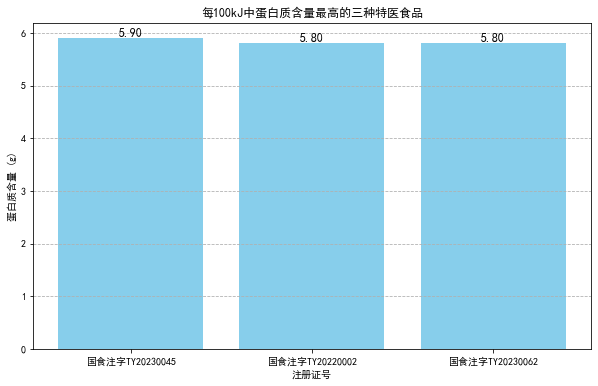

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['font.sans-serif']=['SimHei'] # 中文支持
plt.rcParams['axes.unicode_minus']=False

# 绘制带标签的柱状图
plt.figure(figsize=(10, 6))
bars = plt.bar(top3_protein["注册证号"], top3_protein["蛋白质(g)"], color='skyblue')
plt.title("每100kJ中蛋白质含量最高的三种特医食品")
plt.xlabel("注册证号")
plt.ylabel("蛋白质含量 (g)")
plt.grid(axis='y', linestyle='--')

# 为每个柱状图添加标签
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height, f'{height:.2f}', 
             ha='center', va='bottom', fontsize=12)

plt.show()


In [10]:
result_df.to_excel('result1.xlsx',index=None)

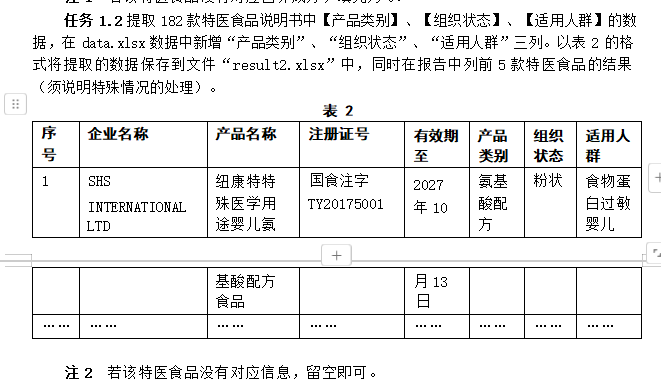

In [11]:
files_list=[]
for file in files:
    if file.endswith(".pdf"):
        file_path = os.path.join(folder_path, file)
    files_list.append(folder_path+file)
files_list

['./特医食品说明书/国食注字TY20175001.pdf',
 './特医食品说明书/国食注字TY20175002.pdf',
 './特医食品说明书/国食注字TY20175003.pdf',
 './特医食品说明书/国食注字TY20180001.pdf',
 './特医食品说明书/国食注字TY20180002.pdf',
 './特医食品说明书/国食注字TY20180003.pdf',
 './特医食品说明书/国食注字TY20180004.pdf',
 './特医食品说明书/国食注字TY20185001.pdf',
 './特医食品说明书/国食注字TY20185002.pdf',
 './特医食品说明书/国食注字TY20185003.pdf',
 './特医食品说明书/国食注字TY20185004.pdf',
 './特医食品说明书/国食注字TY20185005.pdf',
 './特医食品说明书/国食注字TY20185006.pdf',
 './特医食品说明书/国食注字TY20185007.pdf',
 './特医食品说明书/国食注字TY20185009.pdf',
 './特医食品说明书/国食注字TY20185010.pdf',
 './特医食品说明书/国食注字TY20185011.pdf',
 './特医食品说明书/国食注字TY20185012.pdf',
 './特医食品说明书/国食注字TY20185013.pdf',
 './特医食品说明书/国食注字TY20190001.pdf',
 './特医食品说明书/国食注字TY20190002.pdf',
 './特医食品说明书/国食注字TY20190003.pdf',
 './特医食品说明书/国食注字TY20190004.pdf',
 './特医食品说明书/国食注字TY20190005.pdf',
 './特医食品说明书/国食注字TY20190006.pdf',
 './特医食品说明书/国食注字TY20190007.pdf',
 './特医食品说明书/国食注字TY20190008.pdf',
 './特医食品说明书/国食注字TY20190010.pdf',
 './特医食品说明书/国食注字TY20195001.pdf',
 './特医食品说明书/国食注字TY20195002.pdf',
 './特医食品说明

In [12]:
import pdfplumber
import pandas as pd

def extract_info_from_pdf(file_path):
    # 打开 PDF 文件
    with pdfplumber.open(file_path) as pdf:
        text = ''
        for page in pdf.pages:
            text += page.extract_text()
    
    # 提取信息
    product_category = extract_field(text, "【产品类别】", "【配料表】")
    organization_state = extract_field(text, "【组织状态】", "【适用人群】")
    target_population = extract_field(text, "【适用人群】", "【食用方法和食用量】")
    
    return product_category, organization_state, target_population

def extract_field(text, start_key, end_key):
    # 提取特定字段信息
    try:
        start_idx = text.index(start_key) + len(start_key)
        end_idx = text.index(end_key)
        return text[start_idx:end_idx].strip()
    except ValueError:
        return ""

def process_files(files_list):
    data = []
    for file in files_list:
        product_category, organization_state, target_population = extract_info_from_pdf(file)
        data.append({
            "序号": len(data) + 1,
            "企业名称": "未知",
            "产品名称": "未知",
            "注册证号": file.split('/')[-1].split('.')[0],  # 使用文件名作为注册证号
            "有效期至": "未知",
            "产品类别": product_category,
            "组织状态": organization_state,
            "适用人群": target_population
        })
    return pd.DataFrame(data)

# 处理文件并保存结果

df = process_files(files_list)

df

,序号,企业名称,产品名称,注册证号,有效期至,产品类别,组织状态,适用人群
0,1,未知,未知,国食注字TY20175001,未知,氨基酸配方,粉状,食物蛋白过敏婴儿
1,2,未知,未知,国食注字TY20175002,未知,乳蛋白部分水解配方,粉状,0～12月龄乳蛋白过敏高风险婴儿
2,3,未知,未知,国食注字TY20175003,未知,乳蛋白部分水解配方,粉状,0-12月龄乳蛋白过敏高风险婴儿
3,4,未知,未知,国食注字TY20180001,未知,无乳糖配方,粉状,0～12月龄乳糖不耐受婴儿
4,5,未知,未知,国食注字TY20180002,未知,非全营养配方食品,液态,10岁以上因腹泻等原因导致轻至中度脱水需要补充水及电解质的人群。
...,...,...,...,...,...,...,...,...
177,178,未知,未知,国食注字TY20240018,未知,全营养配方食品,液态,10岁以上进食受限、消化吸收障碍、代谢紊乱等需要补充营养的人群。
178,179,未知,未知,国食注字TY20240019,未知,非全营养配方食品,液态,10岁以上特定疾病或医学状况下需要补充蛋白质的人群。
179,180,未知,未知,国食注字TY20240020,未知,脂肪（脂肪酸）组件,粉状,1岁以上特定疾病或者医学状况下需要补充中链脂肪的人群。
180,181,未知,未知,国食注字TY20240021,未知,增稠组件,粉状,10岁以上吞咽障碍和（或）有误吸风险的人群。


In [13]:
df[['产品类别', '组织状态', '适用人群']]

,产品类别,组织状态,适用人群
0,氨基酸配方,粉状,食物蛋白过敏婴儿
1,乳蛋白部分水解配方,粉状,0～12月龄乳蛋白过敏高风险婴儿
2,乳蛋白部分水解配方,粉状,0-12月龄乳蛋白过敏高风险婴儿
3,无乳糖配方,粉状,0～12月龄乳糖不耐受婴儿
4,非全营养配方食品,液态,10岁以上因腹泻等原因导致轻至中度脱水需要补充水及电解质的人群。
...,...,...,...
177,全营养配方食品,液态,10岁以上进食受限、消化吸收障碍、代谢紊乱等需要补充营养的人群。
178,非全营养配方食品,液态,10岁以上特定疾病或医学状况下需要补充蛋白质的人群。
179,脂肪（脂肪酸）组件,粉状,1岁以上特定疾病或者医学状况下需要补充中链脂肪的人群。
180,增稠组件,粉状,10岁以上吞咽障碍和（或）有误吸风险的人群。


In [14]:
data_df = pd.read_excel('data.xlsx')
data_df

,企业名称,产品名称,注册证号,有效期至
0,SHS INTERNATIONAL LTD,纽康特特殊医学用途婴儿氨基酸配方食品,国食注字TY20175001,2027-10-13
1,ABBOTT LABORATORIES S.A.,雅培亲护特殊医学用途婴儿乳蛋白部分水解配方粉,国食注字TY20175002,2027-10-13
2,ABBOTT LABORATORIES S.A.,菁挚呵护特殊医学用途婴儿乳蛋白部分水解配方粉,国食注字TY20175003,2022-11-19
3,杭州贝因美母婴营养品有限公司,贝因美特殊医学用途婴儿无乳糖配方食品,国食注字TY20180001,2028-01-17
4,SHS INTERNATIONAL LTD,纽贝瑞特殊医学用途婴儿苯丙酮尿症配方粉,国食注字TY20185001,2028-01-17
...,...,...,...,...
177,费森尤斯卡比华瑞制药有限公司,德瑞清®特殊医学用途流质配方食品,国食注字TY20240017,2028-12-13
178,江苏冬泽特医食品有限公司,冬泽益全特殊医学用途全营养配方食品,国食注字TY20240018,2029-04-01
179,江苏冬泽特医食品有限公司,冬泽力亮特殊医学用途蛋白质组件配方食品,国食注字TY20240019,2029-04-01
180,江苏冬泽特医食品有限公司,冬泽益能特殊医学用途脂肪组件配方食品,国食注字TY20240020,2029-04-01


In [15]:
data_df=pd.concat([data_df,df[['产品类别', '组织状态', '适用人群']]],axis=1)
data_df

,企业名称,产品名称,注册证号,有效期至,产品类别,组织状态,适用人群
0,SHS INTERNATIONAL LTD,纽康特特殊医学用途婴儿氨基酸配方食品,国食注字TY20175001,2027-10-13,氨基酸配方,粉状,食物蛋白过敏婴儿
1,ABBOTT LABORATORIES S.A.,雅培亲护特殊医学用途婴儿乳蛋白部分水解配方粉,国食注字TY20175002,2027-10-13,乳蛋白部分水解配方,粉状,0～12月龄乳蛋白过敏高风险婴儿
2,ABBOTT LABORATORIES S.A.,菁挚呵护特殊医学用途婴儿乳蛋白部分水解配方粉,国食注字TY20175003,2022-11-19,乳蛋白部分水解配方,粉状,0-12月龄乳蛋白过敏高风险婴儿
3,杭州贝因美母婴营养品有限公司,贝因美特殊医学用途婴儿无乳糖配方食品,国食注字TY20180001,2028-01-17,无乳糖配方,粉状,0～12月龄乳糖不耐受婴儿
4,SHS INTERNATIONAL LTD,纽贝瑞特殊医学用途婴儿苯丙酮尿症配方粉,国食注字TY20185001,2028-01-17,非全营养配方食品,液态,10岁以上因腹泻等原因导致轻至中度脱水需要补充水及电解质的人群。
...,...,...,...,...,...,...,...
177,费森尤斯卡比华瑞制药有限公司,德瑞清®特殊医学用途流质配方食品,国食注字TY20240017,2028-12-13,全营养配方食品,液态,10岁以上进食受限、消化吸收障碍、代谢紊乱等需要补充营养的人群。
178,江苏冬泽特医食品有限公司,冬泽益全特殊医学用途全营养配方食品,国食注字TY20240018,2029-04-01,非全营养配方食品,液态,10岁以上特定疾病或医学状况下需要补充蛋白质的人群。
179,江苏冬泽特医食品有限公司,冬泽力亮特殊医学用途蛋白质组件配方食品,国食注字TY20240019,2029-04-01,脂肪（脂肪酸）组件,粉状,1岁以上特定疾病或者医学状况下需要补充中链脂肪的人群。
180,江苏冬泽特医食品有限公司,冬泽益能特殊医学用途脂肪组件配方食品,国食注字TY20240020,2029-04-01,增稠组件,粉状,10岁以上吞咽障碍和（或）有误吸风险的人群。


In [16]:
# 输出前5条记录作为报告
print("前 5 款特医食品提取结果:")
data_df.head(5)

前 5 款特医食品提取结果:


,企业名称,产品名称,注册证号,有效期至,产品类别,组织状态,适用人群
0,SHS INTERNATIONAL LTD,纽康特特殊医学用途婴儿氨基酸配方食品,国食注字TY20175001,2027-10-13,氨基酸配方,粉状,食物蛋白过敏婴儿
1,ABBOTT LABORATORIES S.A.,雅培亲护特殊医学用途婴儿乳蛋白部分水解配方粉,国食注字TY20175002,2027-10-13,乳蛋白部分水解配方,粉状,0～12月龄乳蛋白过敏高风险婴儿
2,ABBOTT LABORATORIES S.A.,菁挚呵护特殊医学用途婴儿乳蛋白部分水解配方粉,国食注字TY20175003,2022-11-19,乳蛋白部分水解配方,粉状,0-12月龄乳蛋白过敏高风险婴儿
3,杭州贝因美母婴营养品有限公司,贝因美特殊医学用途婴儿无乳糖配方食品,国食注字TY20180001,2028-01-17,无乳糖配方,粉状,0～12月龄乳糖不耐受婴儿
4,SHS INTERNATIONAL LTD,纽贝瑞特殊医学用途婴儿苯丙酮尿症配方粉,国食注字TY20185001,2028-01-17,非全营养配方食品,液态,10岁以上因腹泻等原因导致轻至中度脱水需要补充水及电解质的人群。


In [ ]:
# 保存结果到 result2.xlsx
data_df.to_excel('result2.xlsx', index=False)

In [17]:
data_df['适用人群']

0                              食物蛋白过敏婴儿
1                      0～12月龄乳蛋白过敏高风险婴儿
2                      0-12月龄乳蛋白过敏高风险婴儿
3                         0～12月龄乳糖不耐受婴儿
4      10岁以上因腹泻等原因导致轻至中度脱水需要补充水及电解质的人群。
                     ...               
177    10岁以上进食受限、消化吸收障碍、代谢紊乱等需要补充营养的人群。
178          10岁以上特定疾病或医学状况下需要补充蛋白质的人群。
179         1岁以上特定疾病或者医学状况下需要补充中链脂肪的人群。
180              10岁以上吞咽障碍和（或）有误吸风险的人群。
181                    0～12月龄乳蛋白过敏高风险婴儿
Name: 适用人群, Length: 182, dtype: object

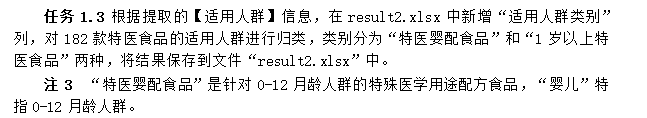

In [18]:
import pandas as pd

def classify_target_population(row):
    """根据'适用人群'进行分类"""
    population = str(row).strip()
    if any(keyword in population for keyword in ['0-12月龄', '婴儿']):
        return '特医婴配食品'
    else:
        return '1 岁以上特医食品'



# 新增“适用人群类别”列，根据适用人群分类
data_df['适用人群类别'] = data_df['适用人群'].apply(classify_target_population)


# 打印前5条记录作为验证
print("前 5 条分类结果：")
data_df[['适用人群', '适用人群类别']].head()


前 5 条分类结果：


,适用人群,适用人群类别
0,食物蛋白过敏婴儿,特医婴配食品
1,0～12月龄乳蛋白过敏高风险婴儿,特医婴配食品
2,0-12月龄乳蛋白过敏高风险婴儿,特医婴配食品
3,0～12月龄乳糖不耐受婴儿,特医婴配食品
4,10岁以上因腹泻等原因导致轻至中度脱水需要补充水及电解质的人群。,1 岁以上特医食品


In [19]:
# 保存结果到 result2.xlsx
data_df.to_excel('result2.xlsx', index=False)

In [20]:
data_df['注册证号']

0      国食注字TY20175001
1      国食注字TY20175002
2      国食注字TY20175003
3      国食注字TY20180001
4      国食注字TY20185001
            ...      
177    国食注字TY20240017
178    国食注字TY20240018
179    国食注字TY20240019
180    国食注字TY20240020
181    国食注字TY20240021
Name: 注册证号, Length: 182, dtype: object

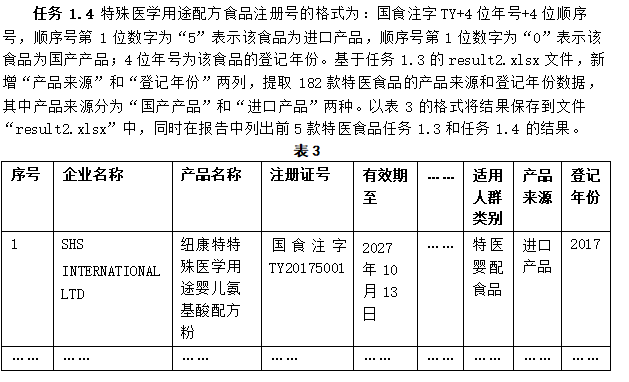

In [21]:
import pandas as pd
import re

def extract_product_info(row):
    """从注册证号中提取产品来源和登记年份"""
    # 使用正则表达式提取年号和顺序号
    match = re.search(r'TY(\d{4})(\d{4})', row)
    if match:
        year = match.group(1)
        serial_number = match.group(2)
        # 根据顺序号的第 1 位判断产品来源
        if serial_number.startswith('5'):
            source = '进口产品'
        elif serial_number.startswith('0'):
            source = '国产产品'
        else:
            source = '未知'
        return source, year
    else:
        return None, None


# 新增“产品来源”和“登记年份”两列
data_df[['产品来源', '登记年份']] = data_df['注册证号'].apply(lambda x: pd.Series(extract_product_info(x)))

data_df


,企业名称,产品名称,注册证号,有效期至,产品类别,组织状态,适用人群,适用人群类别,产品来源,登记年份
0,SHS INTERNATIONAL LTD,纽康特特殊医学用途婴儿氨基酸配方食品,国食注字TY20175001,2027-10-13,氨基酸配方,粉状,食物蛋白过敏婴儿,特医婴配食品,进口产品,2017
1,ABBOTT LABORATORIES S.A.,雅培亲护特殊医学用途婴儿乳蛋白部分水解配方粉,国食注字TY20175002,2027-10-13,乳蛋白部分水解配方,粉状,0～12月龄乳蛋白过敏高风险婴儿,特医婴配食品,进口产品,2017
2,ABBOTT LABORATORIES S.A.,菁挚呵护特殊医学用途婴儿乳蛋白部分水解配方粉,国食注字TY20175003,2022-11-19,乳蛋白部分水解配方,粉状,0-12月龄乳蛋白过敏高风险婴儿,特医婴配食品,进口产品,2017
3,杭州贝因美母婴营养品有限公司,贝因美特殊医学用途婴儿无乳糖配方食品,国食注字TY20180001,2028-01-17,无乳糖配方,粉状,0～12月龄乳糖不耐受婴儿,特医婴配食品,国产产品,2018
4,SHS INTERNATIONAL LTD,纽贝瑞特殊医学用途婴儿苯丙酮尿症配方粉,国食注字TY20185001,2028-01-17,非全营养配方食品,液态,10岁以上因腹泻等原因导致轻至中度脱水需要补充水及电解质的人群。,1 岁以上特医食品,进口产品,2018
...,...,...,...,...,...,...,...,...,...,...
177,费森尤斯卡比华瑞制药有限公司,德瑞清®特殊医学用途流质配方食品,国食注字TY20240017,2028-12-13,全营养配方食品,液态,10岁以上进食受限、消化吸收障碍、代谢紊乱等需要补充营养的人群。,1 岁以上特医食品,国产产品,2024
178,江苏冬泽特医食品有限公司,冬泽益全特殊医学用途全营养配方食品,国食注字TY20240018,2029-04-01,非全营养配方食品,液态,10岁以上特定疾病或医学状况下需要补充蛋白质的人群。,1 岁以上特医食品,国产产品,2024
179,江苏冬泽特医食品有限公司,冬泽力亮特殊医学用途蛋白质组件配方食品,国食注字TY20240019,2029-04-01,脂肪（脂肪酸）组件,粉状,1岁以上特定疾病或者医学状况下需要补充中链脂肪的人群。,1 岁以上特医食品,国产产品,2024
180,江苏冬泽特医食品有限公司,冬泽益能特殊医学用途脂肪组件配方食品,国食注字TY20240020,2029-04-01,增稠组件,粉状,10岁以上吞咽障碍和（或）有误吸风险的人群。,1 岁以上特医食品,国产产品,2024


In [22]:
data_df.head()

,企业名称,产品名称,注册证号,有效期至,产品类别,组织状态,适用人群,适用人群类别,产品来源,登记年份
0,SHS INTERNATIONAL LTD,纽康特特殊医学用途婴儿氨基酸配方食品,国食注字TY20175001,2027-10-13,氨基酸配方,粉状,食物蛋白过敏婴儿,特医婴配食品,进口产品,2017
1,ABBOTT LABORATORIES S.A.,雅培亲护特殊医学用途婴儿乳蛋白部分水解配方粉,国食注字TY20175002,2027-10-13,乳蛋白部分水解配方,粉状,0～12月龄乳蛋白过敏高风险婴儿,特医婴配食品,进口产品,2017
2,ABBOTT LABORATORIES S.A.,菁挚呵护特殊医学用途婴儿乳蛋白部分水解配方粉,国食注字TY20175003,2022-11-19,乳蛋白部分水解配方,粉状,0-12月龄乳蛋白过敏高风险婴儿,特医婴配食品,进口产品,2017
3,杭州贝因美母婴营养品有限公司,贝因美特殊医学用途婴儿无乳糖配方食品,国食注字TY20180001,2028-01-17,无乳糖配方,粉状,0～12月龄乳糖不耐受婴儿,特医婴配食品,国产产品,2018
4,SHS INTERNATIONAL LTD,纽贝瑞特殊医学用途婴儿苯丙酮尿症配方粉,国食注字TY20185001,2028-01-17,非全营养配方食品,液态,10岁以上因腹泻等原因导致轻至中度脱水需要补充水及电解质的人群。,1 岁以上特医食品,进口产品,2018


In [23]:
# 保存更新后的文件
data_df.to_excel('result2.xlsx', index=False)
